# 06 Evaluation and model selection

Issues #18, #19 and #20, phase 2. Scores every model on the SST-5 test set and the frozen marketplace test set (`market-test-frozen`), measures efficiency on CPU, checks calibration, applies the decision rule and exports the selected model.

Run on a **T4 GPU runtime**. The GPU is used only to produce marketplace predictions for the transformers; every latency and memory figure is measured on CPU with one thread.

## Decision rule (final form, fixed 12 November 2026, before any model was scored on the marketplace set)

The rule drafted in the ML handover is kept, with its thresholds unchanged, and one criterion added.

1. **Accuracy.** DistilBERT is deployed if its mean marketplace macro-F1 across three seeds is within 3 points of the best model's mean.
2. **Speed.** The deployed form must have a p95 CPU latency under 300 ms per review: batch size 1, one CPU thread, 20 warm-up predictions, then 300 marketplace reviews.
3. **Memory (added 12 November 2026).** The deployed form must fit a Render free-tier service (512 MB). It is measured as the peak resident memory of a fresh Python process that loads the exported model and tokenizer and classifies 300 reviews. The limit is 400 MB, leaving headroom for the FastAPI application.

If DistilBERT fails criterion 1, the best-scoring model that meets criteria 2 and 3 is deployed.

**Deployed form.** Transformers are exported to ONNX. The int8 dynamically quantised version is used if its marketplace macro-F1 is within 1 point of the fp32 export for the same seed; otherwise the fp32 export is used. The exported seed is the one whose marketplace macro-F1 is closest to the model's three-seed mean, not the best seed.

The memory criterion was added after the SST-5 results showed RoBERTa ahead of DistilBERT by 4.8 points, because the original rule had no check that a model can run on the deployment host. The accuracy and speed thresholds are as drafted in the handover.

In [1]:
import subprocess, sys, warnings, logging
warnings.filterwarnings('ignore'); logging.getLogger().setLevel(logging.ERROR)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnx', 'onnxruntime', 'onnxscript'], check=True)

import tensorflow as tf
tf.config.set_visible_devices([], 'GPU')        # Keras stays on CPU so PyTorch keeps the GPU

from google.colab import drive
drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/capstone-ml'
DATA, PRED, MODELS, LOGS = (f'{ROOT}/{d}' for d in ['data', 'predictions', 'models', 'logs'])
FIGS = f'{ROOT}/figures'
WORK = '/content/eval'

import os, importlib.metadata as md, torch
os.makedirs(FIGS, exist_ok=True); os.makedirs(WORK, exist_ok=True)
print('Python', sys.version.split()[0])
for p in ['torch', 'transformers', 'tensorflow', 'keras', 'onnx', 'onnxruntime', 'onnxscript', 'scikit-learn', 'pandas', 'numpy']:
    print(f'{p}=={md.version(p)}')
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE, switch the runtime to T4')

Mounted at /content/drive
Python 3.13.16
torch==2.14.1+cu130
transformers==5.22.1
tensorflow==2.21.0
keras==3.13.2
onnx==1.23.2
onnxruntime==1.31.1
onnxscript==0.7.2
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
GPU: Tesla T4


## 1. Data and the models under test

In [2]:
import json, glob, time, re
import numpy as np
import pandas as pd

splits = {s: pd.read_csv(f'{DATA}/sst5_{s}.csv') for s in ['train', 'val', 'test']}
market = pd.read_csv(f'{DATA}/market_test.csv')
assert len(market) == 390 and market['label'].value_counts().sort_index().tolist() == [120, 146, 124]
assert splits['train']['label'].value_counts().sort_index().tolist() == [3310, 1624, 3610]

SEEDS = [42, 43, 44]
MODELS_UNDER_TEST = ['svm', 'lstm', 'distilbert', 'roberta']
NAMES = ['negative', 'neutral', 'positive']
print('Marketplace:', len(market), 'reviews,', market['label'].map(dict(enumerate(NAMES))).value_counts().to_dict())

missing = [f for m in MODELS_UNDER_TEST for f in ([f'{PRED}/svm_sst5_test.csv'] if m == 'svm' else
           [f'{PRED}/{m}_seed{s}_sst5_test.csv' for s in SEEDS]) if not os.path.exists(f)]
print('Missing SST-5 prediction files:', missing or 'none')

Marketplace: 390 reviews, {'neutral': 146, 'positive': 124, 'negative': 120}
Missing SST-5 prediction files: none


## 2. Marketplace predictions for every model and seed

This is the first time any model sees `market_test.csv`. Predictions are written in the shared format, next to the SST-5 ones.

In [3]:
import joblib

def write_preds(df, proba, model, seed, eval_set):
    out = pd.DataFrame({'id': df['id'], 'true_label': df['label'], 'pred_label': proba.argmax(axis=1),
                        'p_neg': proba[:, 0].round(6), 'p_neu': proba[:, 1].round(6), 'p_pos': proba[:, 2].round(6),
                        'model': model, 'seed': seed, 'train_data': 'sst5', 'eval_set': eval_set})
    name = f'{model}_market_test.csv' if seed == '' else f'{model}_seed{seed}_market_test.csv'
    out.to_csv(f'{PRED}/{name}', index=False)
    return out

# SVM: the saved pipeline holds the vectorizer and the model; labels come from the decision function, as in 02
svm = joblib.load(f'{MODELS}/svm.joblib')
p = svm.predict_proba(market['text'])
svm_pred = svm.predict(market['text'])
out = write_preds(market, p, 'svm', '', 'market_test'); out['pred_label'] = svm_pred
out.to_csv(f'{PRED}/svm_market_test.csv', index=False)
print('SVM done')

SVM done


In [4]:
# LSTM: rebuild the tokenizer and vocabulary exactly as in 03_lstm (deterministic from the same files)
import keras
from keras.utils import pad_sequences
from collections import Counter

def glove_tokens(text):
    t = re.sub(r"n't\b", " n't", text)
    t = re.sub(r"'(s|re|ve|ll|d|m)\b", r" '\1", t)
    t = re.sub(r'([.,!?;:()"])', r' \1 ', t)
    return t.split()

glove = {}
with open(f'{DATA}/glove.6B.100d.txt', encoding='utf8') as f:
    for line in f:
        word, *vec = line.rstrip().split(' ')
        glove[word] = None
train_counts = Counter(w for t in splits['train']['text'] for w in glove_tokens(t))
top_glove = list(glove)[:100_000]
train_words = [w for w, _ in train_counts.most_common() if w in glove]
word_index = {w: i + 2 for i, w in enumerate(dict.fromkeys(train_words + top_glove))}
assert len(word_index) == 101_583, len(word_index)
del glove

def lstm_input(texts):
    return pad_sequences([[word_index.get(w, 1) for w in glove_tokens(t)] for t in texts],
                         maxlen=64, padding='post', truncating='pre')

X_market = lstm_input(market['text'])
unknown = (np.concatenate([[word_index.get(w, 1) for w in glove_tokens(t)] for t in market['text']]) == 1).mean()
over64 = np.mean([len(glove_tokens(t)) > 64 for t in market['text']])
print(f'Marketplace tokens unknown to the LSTM: {unknown:.2%}; reviews over 64 tokens (cut at the start): {over64:.2%}')

lstm_models = {}
for s in SEEDS:
    lstm_models[s] = keras.models.load_model(f'{MODELS}/lstm_seed{s}.keras')
    write_preds(market, lstm_models[s].predict(X_market, verbose=0), 'lstm', s, 'market_test')
print('LSTM done')

Marketplace tokens unknown to the LSTM: 1.04%; reviews over 64 tokens (cut at the start): 3.85%
LSTM done


In [5]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

def transformer_proba(model_dir, texts, device='cuda', batch=64):
    tok = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(device).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch):
            enc = tok(list(texts[i:i + batch]), truncation=True, max_length=128, padding=True, return_tensors='pt').to(device)
            out.append(torch.softmax(model(**enc).logits.float(), dim=-1).cpu().numpy())
    del model; torch.cuda.empty_cache()
    return np.concatenate(out)

for m in ['distilbert', 'roberta']:
    for s in SEEDS:
        write_preds(market, transformer_proba(f'{MODELS}/{m}_seed{s}', market['text']), m, s, 'market_test')
    print(m, 'done')

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

distilbert done


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

roberta done


## 3. Accuracy on both test sets

In [6]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix

def pred_files(model, eval_set):
    if model == 'majority': return [('', f'{PRED}/majority_{eval_set}.csv')]
    if model == 'svm': return [('', f'{PRED}/svm_{eval_set}.csv')]
    return [(s, f'{PRED}/{model}_seed{s}_{eval_set}.csv') for s in SEEDS]

rows = []
for eval_set in ['sst5_test', 'market_test']:
    for m in ['majority'] + MODELS_UNDER_TEST:
        for seed, path in pred_files(m, eval_set):
            p = pd.read_csv(path)
            prec, rec, f1, _ = precision_recall_fscore_support(p['true_label'], p['pred_label'], labels=[0, 1, 2], zero_division=0)
            rows.append({'eval_set': eval_set, 'model': m, 'seed': seed, 'accuracy': accuracy_score(p['true_label'], p['pred_label']),
                         'macro_f1': f1.mean(), 'neg_f1': f1[0], 'neu_f1': f1[1], 'pos_f1': f1[2],
                         'neu_precision': prec[1], 'neu_recall': rec[1]})
scores = pd.DataFrame(rows)
cols = ['macro_f1', 'accuracy', 'neg_f1', 'neu_f1', 'pos_f1', 'neu_precision', 'neu_recall']
summary = scores.groupby(['eval_set', 'model'], sort=False)[cols].agg(['mean', 'std']).round(4)
for es in ['sst5_test', 'market_test']:
    print(f'\n=== {es}: mean and std across seeds ===')
    print(summary.loc[es].to_string())
scores.to_csv(f'{LOGS}/evaluation_scores.csv', index=False)


=== sst5_test: mean and std across seeds ===
           macro_f1         accuracy          neg_f1          neu_f1          pos_f1         neu_precision         neu_recall        
               mean     std     mean     std    mean     std    mean     std    mean     std          mean     std       mean     std
model                                                                                                                                
majority     0.1943     NaN   0.4113     NaN  0.0000     NaN  0.0000     NaN  0.5829     NaN        0.0000     NaN     0.0000     NaN
svm          0.5399     NaN   0.6462     NaN  0.6920     NaN  0.1897     NaN  0.7382     NaN        0.2880     NaN     0.1414     NaN
lstm         0.5712  0.0040   0.6302  0.0358  0.6679  0.0558  0.3080  0.0678  0.7376  0.0019        0.3124  0.0615     0.3642  0.1737
distilbert   0.6642  0.0088   0.7226  0.0101  0.7666  0.0189  0.3848  0.0192  0.8412  0.0056        0.3487  0.0174     0.4302  0.0317
roberta      0.7

In [7]:
mean_f1 = scores.groupby(['eval_set', 'model'])['macro_f1'].mean().unstack(0)
mean_f1['drop_from_sst5'] = mean_f1['sst5_test'] - mean_f1['market_test']
print('Mean macro-F1 by test set, and the drop when moving from movie sentences to service reviews:')
print(mean_f1.loc[['majority'] + MODELS_UNDER_TEST].round(4).to_string())

Mean macro-F1 by test set, and the drop when moving from movie sentences to service reviews:
eval_set    market_test  sst5_test  drop_from_sst5
model                                             
majority         0.1608     0.1943          0.0335
svm              0.3802     0.5399          0.1598
lstm             0.4161     0.5712          0.1551
distilbert       0.6603     0.6642          0.0039
roberta          0.7282     0.7125         -0.0157


## 4. Bootstrap confidence intervals on the marketplace set

Each resample draws 390 marketplace reviews with replacement. For a seeded model, the statistic is the mean macro-F1 of its three seeds on that resample, so the interval covers both review sampling and seed variation averaged the way the rule averages them. The DistilBERT and RoBERTa gap uses the same resamples for both models (a paired bootstrap).

In [8]:
def macro_f1_fast(y, p):
    f = []
    for c in range(3):
        tp = np.sum((y == c) & (p == c)); fp = np.sum((y != c) & (p == c)); fn = np.sum((y == c) & (p != c))
        f.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
    return np.mean(f)

y_m = market['label'].values
preds_m = {m: [pd.read_csv(path)['pred_label'].values for _, path in pred_files(m, 'market_test')]
           for m in ['majority'] + MODELS_UNDER_TEST}
rng = np.random.default_rng(2026)
B = 2000
boot = {m: np.empty(B) for m in preds_m}
for b in range(B):
    idx = rng.integers(0, len(y_m), len(y_m))
    for m, plist in preds_m.items():
        boot[m][b] = np.mean([macro_f1_fast(y_m[idx], pr[idx]) for pr in plist])

ci = pd.DataFrame({m: {'mean_macro_f1': np.mean([macro_f1_fast(y_m, pr) for pr in preds_m[m]]),
                       'ci_low': np.percentile(boot[m], 2.5), 'ci_high': np.percentile(boot[m], 97.5)}
                   for m in preds_m}).T.round(4)
print(ci.to_string())

gap = boot['roberta'] - boot['distilbert']
gap_point = ci.loc['roberta', 'mean_macro_f1'] - ci.loc['distilbert', 'mean_macro_f1']
print(f'\nRoBERTa minus DistilBERT: {gap_point:+.4f}, 95% CI [{np.percentile(gap, 2.5):+.4f}, {np.percentile(gap, 97.5):+.4f}], '
      f'share of resamples where RoBERTa is ahead: {np.mean(gap > 0):.1%}')

            mean_macro_f1  ci_low  ci_high
majority           0.1608  0.1414   0.1779
svm                0.3802  0.3299   0.4265
lstm               0.4161  0.3787   0.4524
distilbert         0.6603  0.6181   0.7015
roberta            0.7282  0.6889   0.7654

RoBERTa minus DistilBERT: +0.0679, 95% CI [+0.0300, +0.1060], share of resamples where RoBERTa is ahead: 100.0%


## 5. Where the models go wrong on marketplace reviews

Accuracy on subsets of the marketplace set, using the feature tags recorded when the reviews were drafted. These tags were never shown to any labeller or model.

In [9]:
keys = pd.concat([pd.read_csv(f) for f in glob.glob(f'{DATA}/market_drafting/key_*.csv')]) if glob.glob(f'{DATA}/market_drafting/key_*.csv') else None
if keys is None:
    print('Key files not found in capstone-ml/data/market_drafting/. Skipping the subset analysis.')
else:
    feats = market[['id']].merge(keys[['id', 'features']], on='id', how='left')['features'].fillna('')
    subsets = {'all': np.ones(len(market), bool)}
    for f in ['mixed', 'disagree', 'flat', 'sarcasm', 'long', 'multi']:
        subsets[f] = feats.str.contains(f).values
    subsets['client_to_worker'] = (market['direction'] == 'client_to_worker').values
    subsets['worker_to_client'] = (market['direction'] == 'worker_to_client').values
    table = {}
    for m in MODELS_UNDER_TEST:
        table[m] = {name: np.mean([np.mean(pr[mask] == y_m[mask]) for pr in preds_m[m]]) for name, mask in subsets.items()}
    sub = pd.DataFrame(table).round(3)
    sub.insert(0, 'reviews', [int(mask.sum()) for mask in subsets.values()])
    print('Accuracy by subset (mean across seeds):')
    print(sub.to_string())

Accuracy by subset (mean across seeds):
                  reviews    svm   lstm  distilbert  roberta
all                   390  0.390  0.438       0.662    0.728
mixed                 131  0.313  0.354       0.517    0.646
disagree               46  0.348  0.420       0.681    0.783
flat                   43  0.116  0.364       0.783    0.729
sarcasm                10  0.200  0.233       0.167    0.100
long                   15  0.467  0.400       0.644    0.844
multi                 157  0.433  0.471       0.690    0.777
client_to_worker      281  0.388  0.432       0.656    0.728
worker_to_client      109  0.394  0.453       0.676    0.728


## 6. Export the transformer candidates to ONNX

For DistilBERT and RoBERTa, the seed closest to the three-seed marketplace mean is exported, as fp32 and as int8 with dynamic quantisation. Both exports are scored on the marketplace set to check that the conversion kept the model's behaviour.

In [10]:
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic, QuantType

def export_onnx(model_dir, path):
    tok = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir).cpu().eval()
    enc = tok(['an example review to trace the graph.'], return_tensors='pt')
    args = (enc['input_ids'], enc['attention_mask'])
    names = dict(input_names=['input_ids', 'attention_mask'], output_names=['logits'])
    try:
        torch.onnx.export(model, args, path, dynamo=False, opset_version=17,
                          dynamic_axes={'input_ids': {0: 'batch', 1: 'seq'}, 'attention_mask': {0: 'batch', 1: 'seq'},
                                        'logits': {0: 'batch'}}, **names)
    except Exception as e:
        print('  TorchScript exporter unavailable, using the dynamo exporter:', type(e).__name__)
        batch, seq = torch.export.Dim('batch'), torch.export.Dim('seq', max=512)
        torch.onnx.export(model, args, path, dynamo=True, external_data=False,
                          dynamic_shapes={'input_ids': {0: batch, 1: seq}, 'attention_mask': {0: batch, 1: seq}}, **names)
    tok.save_pretrained(os.path.dirname(path))

def onnx_proba(path, model_dir, texts):
    tok = AutoTokenizer.from_pretrained(model_dir)
    so = ort.SessionOptions(); so.intra_op_num_threads = 1
    sess = ort.InferenceSession(path, so, providers=['CPUExecutionProvider'])
    feed = [i.name for i in sess.get_inputs()]
    out = []
    for t in texts:
        enc = tok(t, truncation=True, max_length=128, return_tensors='np')
        logits = sess.run(['logits'], {k: enc[k].astype(np.int64) for k in feed})[0]
        out.append(np.exp(logits - logits.max()) / np.exp(logits - logits.max()).sum())
    return np.concatenate(out)

market_f1 = scores[scores['eval_set'] == 'market_test']
exports = {}
for m in ['distilbert', 'roberta']:
    r = market_f1[market_f1['model'] == m]
    seed = int(r.iloc[(r['macro_f1'] - r['macro_f1'].mean()).abs().argmin()]['seed'])
    d = f'{WORK}/{m}_seed{seed}_onnx'; os.makedirs(d, exist_ok=True)
    fp32, int8 = f'{d}/model_fp32.onnx', f'{d}/model_int8.onnx'
    export_onnx(f'{MODELS}/{m}_seed{seed}', fp32)
    quantize_dynamic(fp32, int8, weight_type=QuantType.QInt8)
    torch_f1 = float(r[r['seed'] == seed]['macro_f1'].iloc[0])
    res = {'seed': seed, 'dir': d, 'pytorch_market_f1': torch_f1}
    for form, path in [('fp32', fp32), ('int8', int8)]:
        res[f'{form}_market_f1'] = macro_f1_fast(y_m, onnx_proba(path, d, market['text']).argmax(axis=1))
        res[f'{form}_mb'] = os.path.getsize(path) / 1e6
    if abs(res['fp32_market_f1'] - torch_f1) > 0.02:
        raise RuntimeError(f'{m}: the fp32 export scores {res["fp32_market_f1"]:.4f} against {torch_f1:.4f} in PyTorch. '
                           'The export changed the model, so stop here and tell Claude.')
    res['form'] = 'int8' if res['fp32_market_f1'] - res['int8_market_f1'] <= 0.01 else 'fp32'
    exports[m] = res
    print(m, {k: (round(v, 4) if isinstance(v, float) else v) for k, v in res.items() if k != 'dir'})

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

distilbert {'seed': 43, 'pytorch_market_f1': 0.6685, 'fp32_market_f1': np.float64(0.6685), 'fp32_mb': 267.9423, 'int8_market_f1': np.float64(0.6589), 'int8_mb': 67.3591, 'form': 'int8'}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

roberta {'seed': 44, 'pytorch_market_f1': 0.7178, 'fp32_market_f1': np.float64(0.7178), 'fp32_mb': 498.8191, 'int8_market_f1': np.float64(0.6991), 'int8_mb': 125.4321, 'form': 'fp32'}


## 7. Efficiency on CPU: latency, size and memory

One CPU thread for every model. Latency is per review at batch size 1, after 20 warm-up predictions, over the first 300 marketplace reviews. Colab's CPU is not Render's, so absolute numbers are re-measured at deployment; the comparison between models is what this table is for.

In [12]:
torch.set_num_threads(1)
try:
    tf.config.threading.set_intra_op_parallelism_threads(1)
except RuntimeError:
    print('Note: TensorFlow was already running, so the LSTM keeps its default threads and its latency is slightly flattering.')
lat_texts = market['text'].tolist()[:300]

def time_it(fn, texts):
    for t in texts[:20]: fn(t)
    times = []
    for t in texts:
        start = time.perf_counter(); fn(t); times.append((time.perf_counter() - start) * 1000)
    return np.median(times), np.percentile(times, 95)

def dir_mb(path):
    return sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(path) for f in fs) / 1e6

eff = {}
eff['svm'] = (*time_it(lambda t: svm.predict_proba([t]), lat_texts), os.path.getsize(f'{MODELS}/svm.joblib') / 1e6)
lm = lstm_models[SEEDS[0]]
eff['lstm'] = (*time_it(lambda t: lm(lstm_input([t]), training=False), lat_texts), os.path.getsize(f'{MODELS}/lstm_seed{SEEDS[0]}.keras') / 1e6)

for m, res in exports.items():
    tok = AutoTokenizer.from_pretrained(res['dir'])
    model = AutoModelForSequenceClassification.from_pretrained(f'{MODELS}/{m}_seed{res["seed"]}').cpu().eval()
    def run(t, tok=tok, model=model):
        with torch.no_grad(): model(**tok(t, truncation=True, max_length=128, return_tensors='pt'))
    eff[f'{m} pytorch fp32'] = (*time_it(run, lat_texts), dir_mb(f'{MODELS}/{m}_seed{res["seed"]}'))
    del model
print('Measured in this process; ONNX forms follow in a separate clean process.')

Note: TensorFlow was already running, so the LSTM keeps its default threads and its latency is slightly flattering.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Measured in this process; ONNX forms follow in a separate clean process.


In [13]:
MEMCHECK = '''
import json, sys, time
import numpy as np, onnxruntime as ort
from tokenizers import Tokenizer
model_path, tok_path, texts_path = sys.argv[1:4]
tok = Tokenizer.from_file(tok_path); tok.enable_truncation(128); tok.no_padding()
so = ort.SessionOptions(); so.intra_op_num_threads = 1
sess = ort.InferenceSession(model_path, so, providers=["CPUExecutionProvider"])
names = [i.name for i in sess.get_inputs()]
texts = json.load(open(texts_path))
def run(t):
    e = tok.encode(t)
    feed = {"input_ids": np.array([e.ids], dtype=np.int64), "attention_mask": np.array([e.attention_mask], dtype=np.int64)}
    return sess.run(["logits"], {k: feed[k] for k in names})[0]
for t in texts[:20]: run(t)
times = []
for t in texts:
    s = time.perf_counter(); run(t); times.append((time.perf_counter() - s) * 1000)
hwm = [l for l in open("/proc/self/status") if l.startswith("VmHWM")][0]
print(json.dumps({"median_ms": float(np.median(times)), "p95_ms": float(np.percentile(times, 95)),
                  "peak_rss_mb": int(hwm.split()[1]) / 1024}))
'''
open(f'{WORK}/memcheck.py', 'w').write(MEMCHECK)
json.dump(lat_texts, open(f'{WORK}/lat_texts.json', 'w'))

memory = {}
for m, res in exports.items():
    for form in ['fp32', 'int8']:
        out = subprocess.run([sys.executable, f'{WORK}/memcheck.py', f'{res["dir"]}/model_{form}.onnx',
                              f'{res["dir"]}/tokenizer.json', f'{WORK}/lat_texts.json'], capture_output=True, text=True)
        if out.returncode != 0:
            print(out.stderr[-2000:]); raise RuntimeError(f'memory check failed for {m} {form}')
        r = json.loads(out.stdout.strip().splitlines()[-1])
        memory[(m, form)] = r
        eff[f'{m} onnx {form}'] = (r['median_ms'], r['p95_ms'], res[f'{form}_mb'])

eff_df = pd.DataFrame(eff, index=['median_ms', 'p95_ms', 'size_mb']).T.round(1)
eff_df['peak_rss_mb'] = [round(memory[(k.split()[0], k.split()[-1])]['peak_rss_mb'], 1) if 'onnx' in k else None for k in eff_df.index]
print(eff_df.to_string())

                         median_ms  p95_ms  size_mb  peak_rss_mb
svm                            4.7     7.0      3.1          NaN
lstm                         516.3   723.8     41.7          NaN
distilbert pytorch fp32       70.5   106.4    268.6          NaN
roberta pytorch fp32         138.1   213.6    502.2          NaN
distilbert onnx fp32          34.7    67.9    267.9        411.5
distilbert onnx int8          19.9    34.1     67.4        161.5
roberta onnx fp32             71.3   125.0    498.8        732.4
roberta onnx int8             43.0    82.2    125.4        239.2


## 8. Calibration of the transformer exports

A model is well calibrated if, among reviews it labels with confidence around 0.9, about 90% are right. Expected calibration error (ECE, 10 bins) measures the gap. Temperature scaling divides the model's scores by one number T, fitted on the SST-5 validation set, which changes the confidence values but never the predicted label. The `confidence_score` stored in the database will use the calibrated values.

In [14]:
from scipy.optimize import minimize_scalar

def ece(proba, y, bins=10):
    conf, pred = proba.max(axis=1), proba.argmax(axis=1)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any(): e += mask.mean() * abs((pred[mask] == y[mask]).mean() - conf[mask].mean())
    return e

def scale(proba, T):
    z = np.log(np.clip(proba, 1e-12, 1)) / T
    z -= z.max(axis=1, keepdims=True)
    return np.exp(z) / np.exp(z).sum(axis=1, keepdims=True)

calib = {}
for m, res in exports.items():
    path = f'{res["dir"]}/model_{res["form"]}.onnx'
    p_val = onnx_proba(path, res['dir'], splits['val']['text'])
    p_mkt = onnx_proba(path, res['dir'], market['text'])
    y_val = splits['val']['label'].values
    nll = lambda T: -np.mean(np.log(np.clip(scale(p_val, T)[np.arange(len(y_val)), y_val], 1e-12, 1)))
    T = float(minimize_scalar(nll, bounds=(0.5, 5.0), method='bounded').x)
    calib[m] = {'temperature': round(T, 4),
                'ece_val_before': ece(p_val, y_val), 'ece_val_after': ece(scale(p_val, T), y_val),
                'ece_market_before': ece(p_mkt, y_m), 'ece_market_after': ece(scale(p_mkt, T), y_m),
                'mean_conf_market_before': p_mkt.max(axis=1).mean(), 'mean_conf_market_after': scale(p_mkt, T).max(axis=1).mean(),
                'market_accuracy': (p_mkt.argmax(axis=1) == y_m).mean()}
print(pd.DataFrame(calib).round(4).to_string())

                         distilbert  roberta
temperature                  1.2984   1.2548
ece_val_before               0.0659   0.0534
ece_val_after                0.0577   0.0432
ece_market_before            0.0389   0.0692
ece_market_after             0.0362   0.0827
mean_conf_market_before      0.6955   0.6846
mean_conf_market_after       0.6366   0.6382
market_accuracy              0.6590   0.7179


## 9. Apply the decision rule

In [15]:
means = ci['mean_macro_f1']
best = means[MODELS_UNDER_TEST].idxmax()
gap_to_best = means[best] - means['distilbert']
print(f'Best mean marketplace macro-F1: {best} ({means[best]:.4f}). DistilBERT: {means["distilbert"]:.4f}, gap {gap_to_best * 100:.2f} points.')

def form_of(m):
    if m in exports: return f'{m} onnx {exports[m]["form"]}'
    return m

def meets(m):
    p95 = eff_df.loc[form_of(m), 'p95_ms']
    rss = memory[(m, exports[m]['form'])]['peak_rss_mb'] if m in exports else None
    ok_speed = p95 < 300
    ok_mem = True if rss is None else rss <= 400
    return ok_speed, ok_mem, p95, rss

for m in MODELS_UNDER_TEST:
    s, mm, p95, rss = meets(m)
    print(f'  {m:10s} mean macro-F1 {means[m]:.4f} | p95 {p95:.1f} ms ({"pass" if s else "FAIL"}) | '
          f'peak memory {"n/a" if rss is None else f"{rss:.0f} MB"} ({"pass" if mm else "FAIL"})')

if gap_to_best <= 0.03 and all(meets('distilbert')[:2]):
    chosen, reason = 'distilbert', 'within 3 points of the best model and meets the speed and memory limits'
else:
    eligible = [m for m in sorted(MODELS_UNDER_TEST, key=lambda m: -means[m]) if all(meets(m)[:2])]
    chosen = eligible[0]
    reason = (f'DistilBERT is {gap_to_best * 100:.2f} points behind {best}, outside the 3-point margin; '
              f'{chosen} is the best-scoring model that meets the speed and memory limits')
print(f'\nDECISION: deploy {chosen}. Reason: {reason}.')

Best mean marketplace macro-F1: roberta (0.7282). DistilBERT: 0.6603, gap 6.79 points.
  svm        mean macro-F1 0.3802 | p95 7.0 ms (pass) | peak memory n/a (pass)
  lstm       mean macro-F1 0.4161 | p95 723.8 ms (FAIL) | peak memory n/a (pass)
  distilbert mean macro-F1 0.6603 | p95 34.1 ms (pass) | peak memory 161 MB (pass)
  roberta    mean macro-F1 0.7282 | p95 125.0 ms (pass) | peak memory 732 MB (FAIL)

DECISION: deploy distilbert. Reason: DistilBERT is 6.79 points behind roberta, outside the 3-point margin; distilbert is the best-scoring model that meets the speed and memory limits.


## 10. Export the selected model and its model card

In [16]:
import shutil
from datetime import date

assert chosen in exports, 'The selected model is not a transformer; export it by hand and tell Claude.'
res = exports[chosen]
version = f'{chosen}-sst5-3cls-v1.0-{date.today():%Y%m%d}-seed{res["seed"]}-onnx-{res["form"]}'
deploy_dir = f'{MODELS}/deployed'
shutil.rmtree(deploy_dir, ignore_errors=True); os.makedirs(deploy_dir)
shutil.copy(f'{res["dir"]}/model_{res["form"]}.onnx', f'{deploy_dir}/model.onnx')
for f in os.listdir(res['dir']):
    if not f.endswith('.onnx'): shutil.copy(f'{res["dir"]}/{f}', deploy_dir)

card = {
    'model_version': version, 'base_checkpoint': 'distilbert-base-uncased' if chosen == 'distilbert' else 'roberta-base',
    'seed': res['seed'], 'format': f'onnx {res["form"]}', 'labels': NAMES, 'max_length': 128,
    'preprocessing': 'clean_text from ml/01_data_prep.ipynb (lowercase, treebank undone)',
    'temperature': calib[chosen]['temperature'],
    'confidence_score': 'max of softmax(log(p) / temperature)',
    'decision': reason,
    'metrics': {'sst5_test_macro_f1_seed': round(float(scores[(scores.eval_set == 'sst5_test') & (scores.model == chosen) & (scores.seed == res['seed'])]['macro_f1'].iloc[0]), 4),
                'market_macro_f1_seed_pytorch': round(res['pytorch_market_f1'], 4),
                'market_macro_f1_seed_exported': round(res[f'{res["form"]}_market_f1'], 4),
                'market_macro_f1_three_seed_mean': round(float(means[chosen]), 4),
                'market_macro_f1_ci95': [round(float(ci.loc[chosen, 'ci_low']), 4), round(float(ci.loc[chosen, 'ci_high']), 4)],
                'ece_market_after_scaling': round(calib[chosen]['ece_market_after'], 4)},
    'efficiency_colab_cpu_1_thread': {'median_ms': round(float(eff_df.loc[form_of(chosen), 'median_ms']), 1),
                                      'p95_ms': round(float(eff_df.loc[form_of(chosen), 'p95_ms']), 1),
                                      'size_mb': round(float(eff_df.loc[form_of(chosen), 'size_mb']), 1),
                                      'peak_rss_mb': round(memory[(chosen, res['form'])]['peak_rss_mb'], 1)},
    'date': date.today().isoformat(),
}
json.dump(card, open(f'{deploy_dir}/model_card.json', 'w'), indent=2)
json.dump(card, open(f'{WORK}/model_card.json', 'w'), indent=2)
print(json.dumps(card, indent=2))
print('\nFiles in', deploy_dir, ':', sorted(os.listdir(deploy_dir)))

{
  "model_version": "distilbert-sst5-3cls-v1.0-20261111-seed43-onnx-int8",
  "base_checkpoint": "distilbert-base-uncased",
  "seed": 43,
  "format": "onnx int8",
  "labels": [
    "negative",
    "neutral",
    "positive"
  ],
  "max_length": 128,
  "preprocessing": "clean_text from ml/01_data_prep.ipynb (lowercase, treebank undone)",
  "temperature": 1.2984,
  "confidence_score": "max of softmax(log(p) / temperature)",
  "decision": "DistilBERT is 6.79 points behind roberta, outside the 3-point margin; distilbert is the best-scoring model that meets the speed and memory limits",
  "metrics": {
    "sst5_test_macro_f1_seed": 0.6541,
    "market_macro_f1_seed_pytorch": 0.6685,
    "market_macro_f1_seed_exported": 0.6589,
    "market_macro_f1_three_seed_mean": 0.6603,
    "market_macro_f1_ci95": [
      0.6181,
      0.7015
    ],
    "ece_market_after_scaling": 0.0362
  },
  "efficiency_colab_cpu_1_thread": {
    "median_ms": 19.9,
    "p95_ms": 34.1,
    "size_mb": 67.4,
    "peak_rss

## 11. Figures for the report

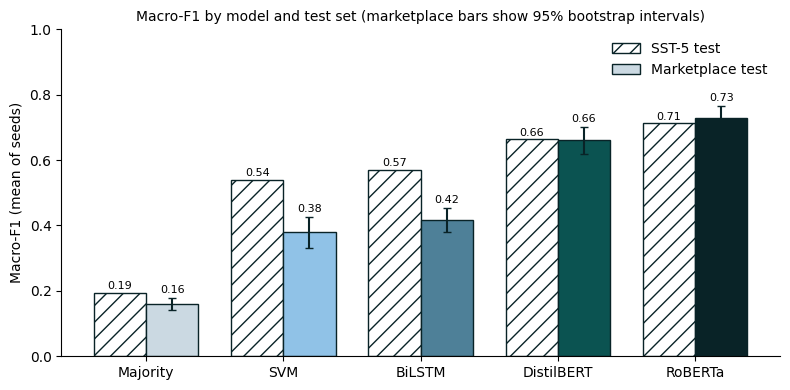

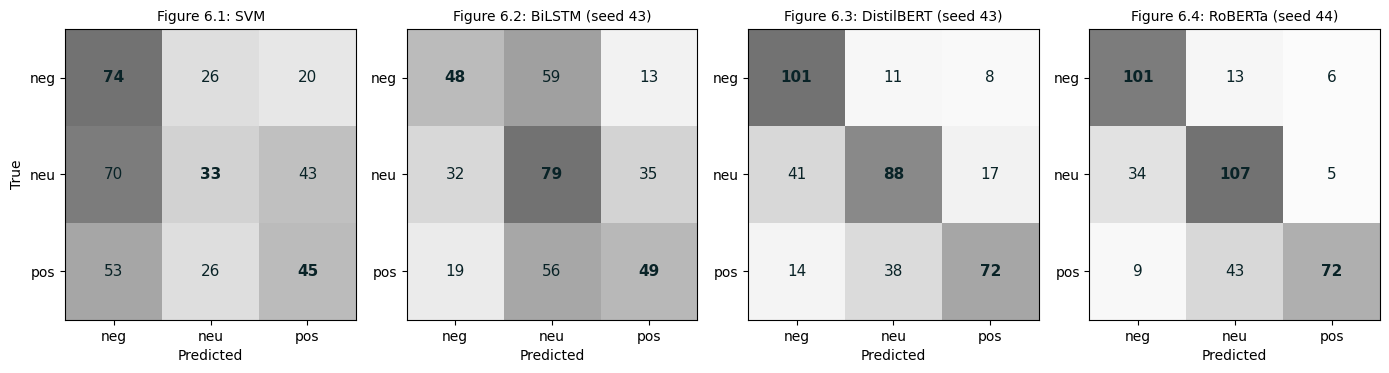

Saved to /content/drive/MyDrive/capstone-ml/figures


In [17]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
PALETTE = {'majority': '#CBD9E2', 'svm': '#90C2E7', 'lstm': '#4E8098', 'distilbert': '#0B5351', 'roberta': '#092327'}
LABELS = {'majority': 'Majority', 'svm': 'SVM', 'lstm': 'BiLSTM', 'distilbert': 'DistilBERT', 'roberta': 'RoBERTa'}
order = ['majority'] + MODELS_UNDER_TEST

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(order)); w = 0.38
sst = mean_f1.loc[order, 'sst5_test']; mkt = ci.loc[order]
ax.bar(x - w / 2, sst, w, color='white', edgecolor='#092327', hatch='//', label='SST-5 test')
ax.bar(x + w / 2, mkt['mean_macro_f1'], w, color=[PALETTE[m] for m in order], edgecolor='#092327', label='Marketplace test')
ax.errorbar(x + w / 2, mkt['mean_macro_f1'], yerr=[mkt['mean_macro_f1'] - mkt['ci_low'], mkt['ci_high'] - mkt['mean_macro_f1']],
            fmt='none', ecolor='#092327', capsize=3)
for i, (a, b) in enumerate(zip(sst, mkt['mean_macro_f1'])):
    ax.text(i - w / 2, a + 0.01, f'{a:.2f}', ha='center', fontsize=8)
    ax.text(i + w / 2, mkt['ci_high'].iloc[i] + 0.015, f'{b:.2f}', ha='center', fontsize=8)
ax.set_xticks(x, [LABELS[m] for m in order]); ax.set_ylabel('Macro-F1 (mean of seeds)'); ax.set_ylim(0, 1)
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Macro-F1 by model and test set (marketplace bars show 95% bootstrap intervals)', fontsize=10)
fig.tight_layout(); fig.savefig(f'{FIGS}/fig6_5_model_comparison.png', dpi=300); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, m, n in zip(axes, MODELS_UNDER_TEST, ['6.1', '6.2', '6.3', '6.4']):
    r = market_f1[market_f1['model'] == m]
    seed = '' if m == 'svm' else int(r.iloc[(r['macro_f1'] - r['macro_f1'].mean()).abs().argmin()]['seed'])
    p = pd.read_csv(f'{PRED}/{m}_market_test.csv' if seed == '' else f'{PRED}/{m}_seed{seed}_market_test.csv')
    cm = confusion_matrix(p['true_label'], p['pred_label'], labels=[0, 1, 2])
    ax.imshow(cm, cmap='Greys', vmin=0, vmax=cm.max() * 1.6)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=11, fontweight='bold' if i == j else 'normal', color='#092327')
    ax.set_xticks(range(3), ['neg', 'neu', 'pos']); ax.set_yticks(range(3), ['neg', 'neu', 'pos'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('True' if m == 'svm' else '')
    ax.set_title(f'Figure {n}: {LABELS[m]}' + ('' if seed == '' else f' (seed {seed})'), fontsize=10)
fig.tight_layout(); fig.savefig(f'{FIGS}/fig6_1-6_4_confusion_matrices_market.png', dpi=300); plt.show()
print('Saved to', FIGS)

In [18]:
from google.colab import files
summary_out = {'sst5_and_market_scores': f'{LOGS}/evaluation_scores.csv', 'bootstrap_ci': ci.to_dict(),
               'roberta_minus_distilbert': {'point': float(gap_point), 'ci95': [float(np.percentile(gap, 2.5)), float(np.percentile(gap, 97.5))]},
               'efficiency': eff_df.reset_index().to_dict(orient='records'), 'calibration': calib,
               'exports': {m: {k: v for k, v in r.items() if k != 'dir'} for m, r in exports.items()}, 'decision': {'chosen': chosen, 'reason': reason}}
json.dump(summary_out, open(f'{LOGS}/evaluation_summary.json', 'w'), indent=2, default=float)
bundle = '/content/ml_eval'; shutil.rmtree(bundle, ignore_errors=True); os.makedirs(f'{bundle}/figures')
shutil.copy(f'{WORK}/model_card.json', bundle); shutil.copy(f'{LOGS}/evaluation_summary.json', bundle)
shutil.copy(f'{LOGS}/evaluation_scores.csv', bundle)
for f in glob.glob(f'{FIGS}/fig6_*.png'): shutil.copy(f, f'{bundle}/figures')
files.download(shutil.make_archive('/content/ml_eval', 'zip', bundle))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>